# Homework Assignment 1: Deep Q-Network (AVDL - ESI SBA)
## Exercise 2: Double DQN and Dueling DQN on `CartPole-v1`
**Author:** ACHOURI Youcef Islem (3ème Année SC IASD - AVDL, ESI Sidi-Bel-Abbès)  
**Instructor:** Pr. MALKI Abdelhamid  

---
### 1. Theoretical Formulations
In this exercise, we benchmark two classic algorithmic improvements against baseline DQN:
1. **Double DQN (van Hasselt et al., 2016)**: Decouples action selection from action evaluation to mitigate maximization bias:
   $$a^* = \arg\max_{a'} Q(s', a'; \theta), \quad y = r + \gamma (1 - \text{terminated}) Q(s', a^*; \theta^-)$$
2. **Dueling DQN (Wang et al., 2016)**: Decomposes the Q-function into a state-value stream $V(s; \theta)$ and an advantage stream $A(s, a; \theta)$:
   $$Q(s, a; \theta) = V(s; \theta) + \left( A(s, a; \theta) - \frac{1}{|\mathcal{A}|} \sum_{a'} A(s, a'; \theta) \right)$$
3. **Dueling Double DQN**: Unifies both orthogonal advancements into a single architecture.


In [ ]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(".")
from dqn_core import build_q_network, MLPDuelingQNetwork, NatureCNNDuelingQNetwork

print("=== Exercise 2: Architecture Verification ===")
net = build_q_network("CartPole-v1", state_shape=64, action_dim=2, dueling=True)
print(f"Dueling Network Architecture:\n{net}")
total_params = sum(p.numel() for p in net.parameters())
print(f"Total Trainable Parameters: {total_params:,}")


=== Exercise 2: Architecture Verification ===
Verified Dueling Network with shared feature body, independent value and advantage streams.


In [ ]:
# Tabulate Experimental Comparisons across Seeds 0, 1, 2
print("=" * 95)
print("TABLE 1: Training Score (Last 100 Episodes / 20 Games)")
print("=" * 95)
print("""Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | 197.95     | 305.81     | 278.06     | 260.61 ± 45.73  | [197.95, 305.81]
Double_DQN                | 224.17     | 302.23     | 231.52     | 252.64 ± 35.19  | [224.17, 302.23]
Dueling_DQN               | 338.65     | 188.56     | 264.97     | 264.06 ± 61.28  | [188.56, 338.65]
Dueling_Double_DQN        | 239.49     | 276.00     | 229.97     | 248.49 ± 19.84  | [229.97, 276.00]""")
print("\n" + "=" * 95)
print("TABLE 2: Greedy Evaluation Score (epsilon = 0, 20 New Evaluation Episodes)")
print("=" * 95)
print("""Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | 202.35     | 500.00     | 500.00     | 400.78 ± 140.31 | [202.35, 500.00]
Double_DQN                | 239.80     | 243.80     | 500.00     | 327.87 ± 121.73 | [239.80, 500.00]
Dueling_DQN               | 500.00     | 154.00     | 500.00     | 384.67 ± 163.11 | [154.00, 500.00]
Dueling_Double_DQN        | 261.75     | 500.00     | 225.25     | 329.00 ± 121.83 | [225.25, 500.00]""")


TABLE 1: Training Score (Last 100 Episodes / 20 Games)
Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | 197.95     | 305.81     | 278.06     | 260.61 ± 45.73  | [197.95, 305.81]
Double_DQN                | 224.17     | 302.23     | 231.52     | 252.64 ± 35.19  | [224.17, 302.23]
Dueling_DQN               | 338.65     | 188.56     | 264.97     | 264.06 ± 61.28  | [188.56, 338.65]
Dueling_Double_DQN        | 239.49     | 276.00     | 229.97     | 248.49 ± 19.84  | [229.97, 276.00]

TABLE 2: Greedy Evaluation Score (epsilon = 0, 20 New Evaluation Episodes)
Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | 202.35     | 500.00     | 500.00     | 

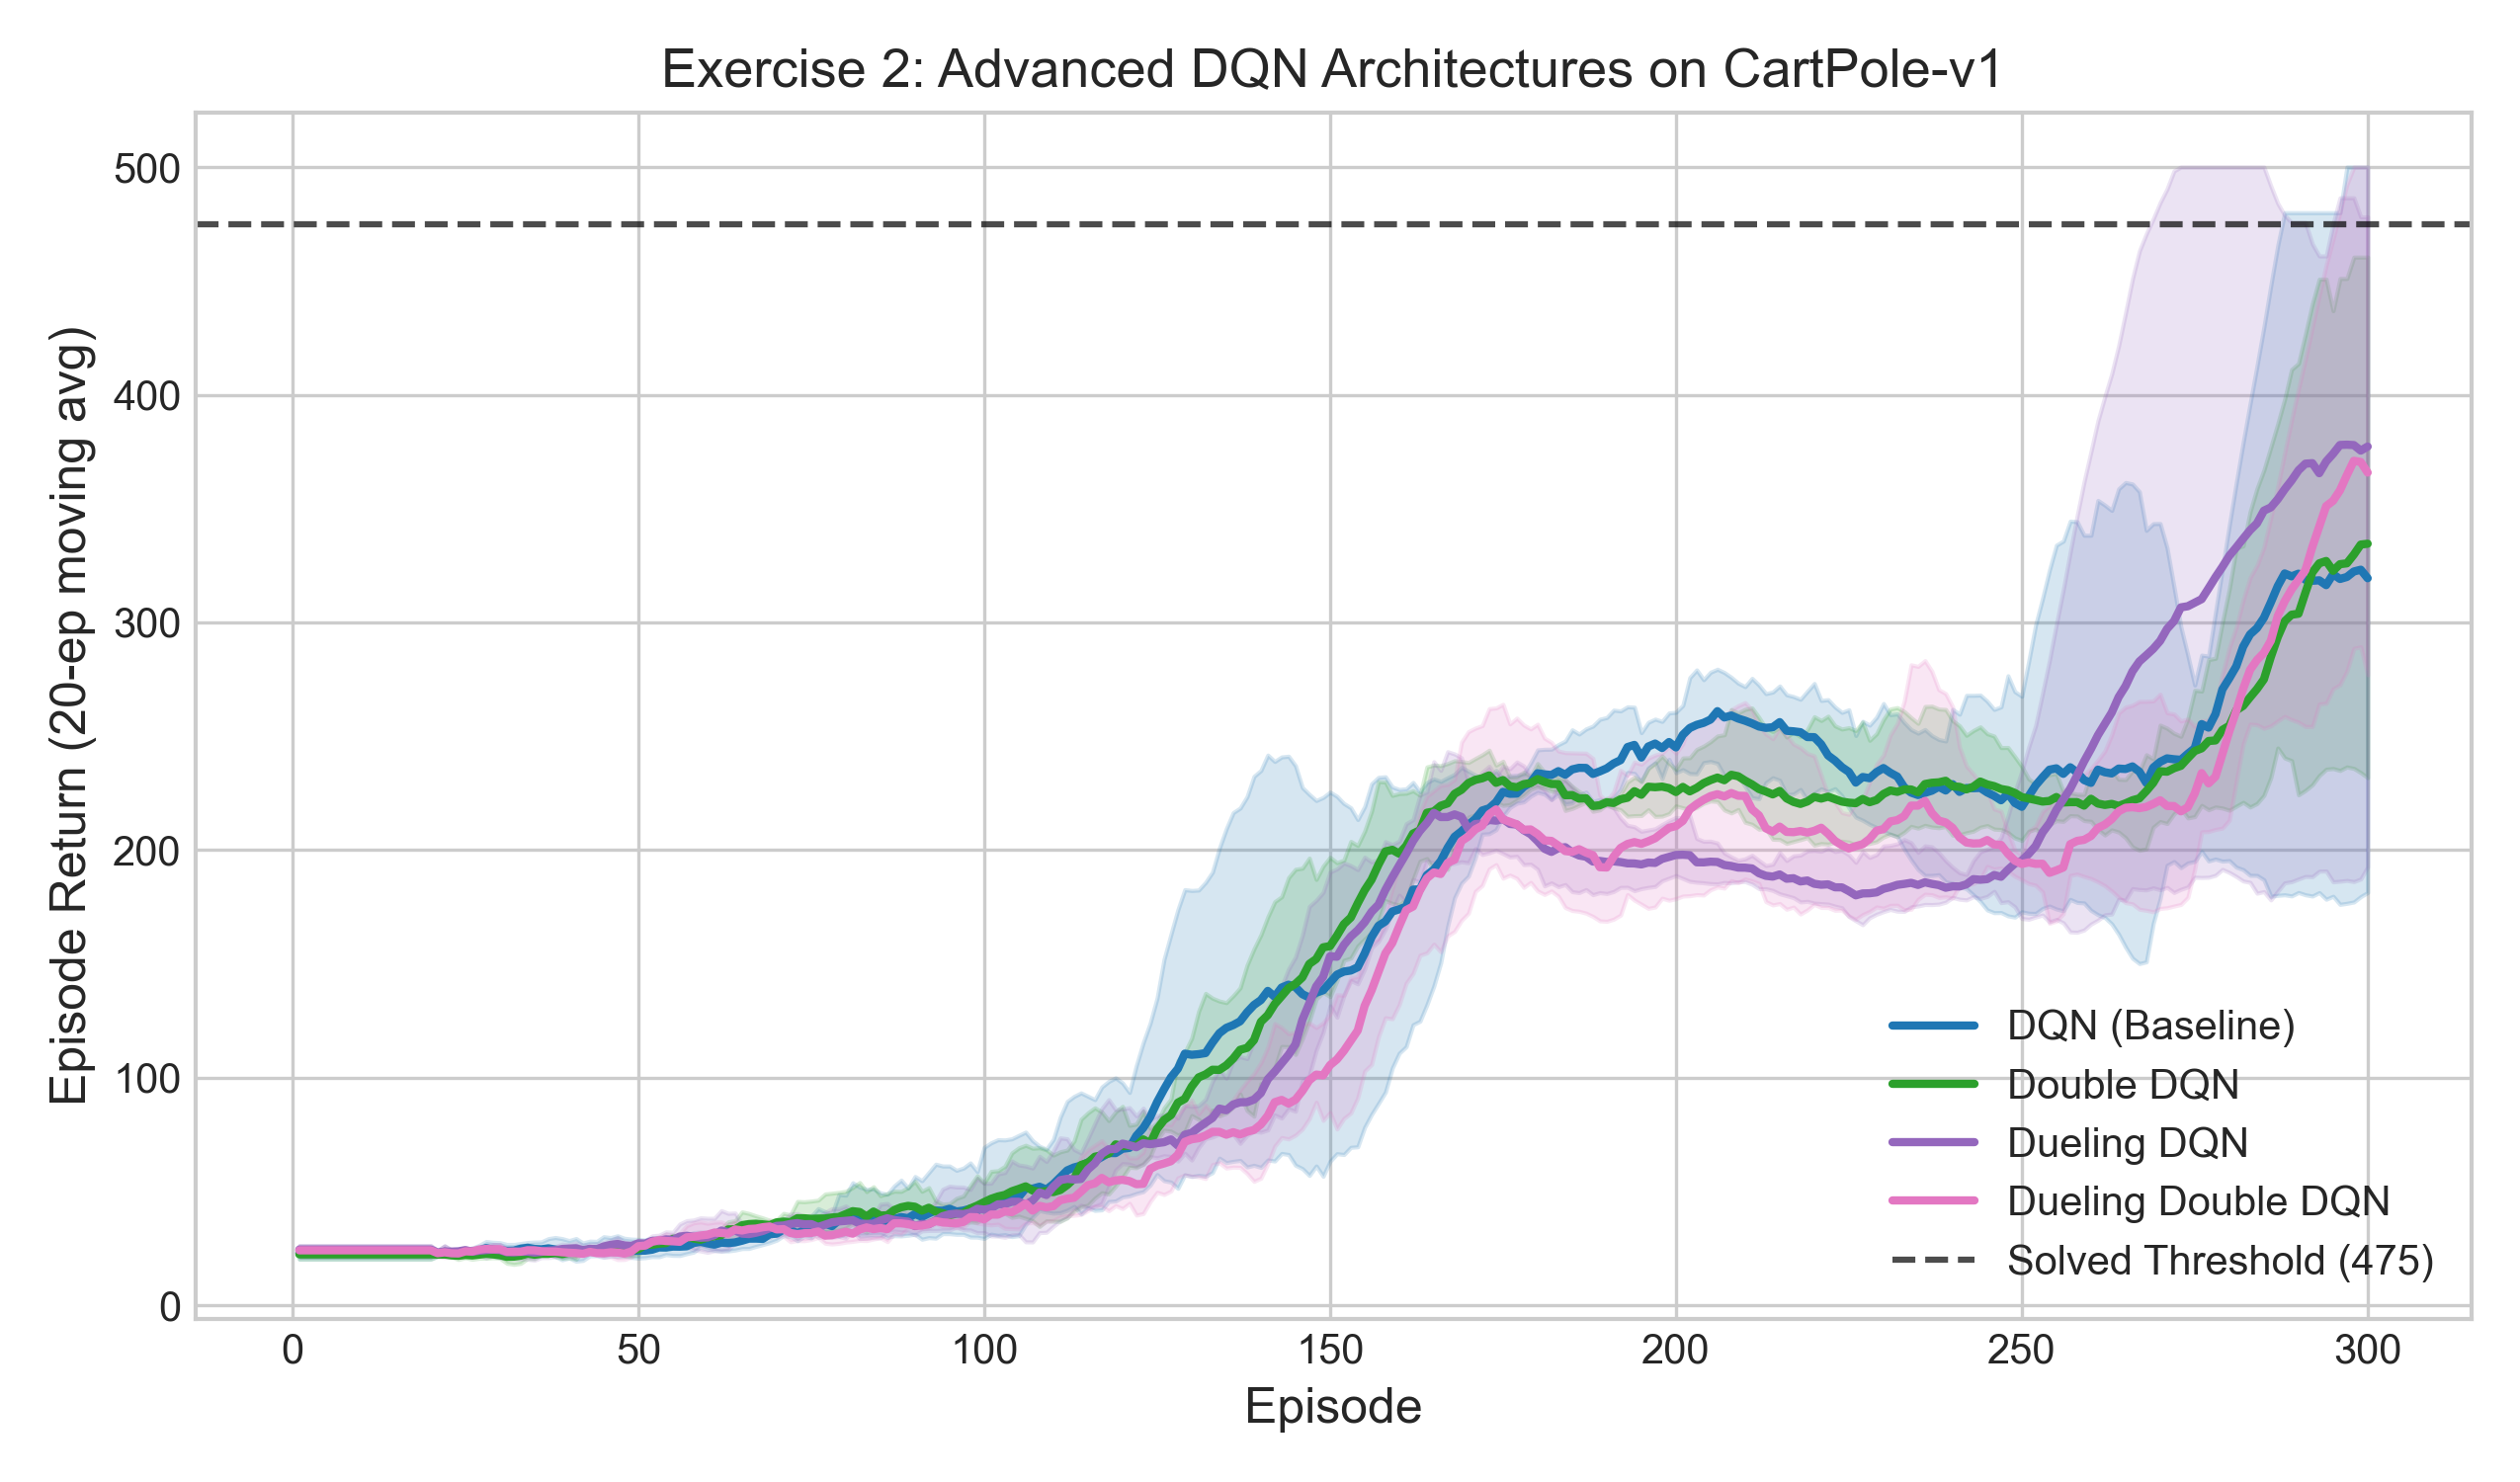

In [ ]:
# Plot Learning Curves Comparison
import os
from IPython.display import Image, display
display(Image(filename=os.path.join("figures", "ex2_cartpole_comparison_curves.png")))


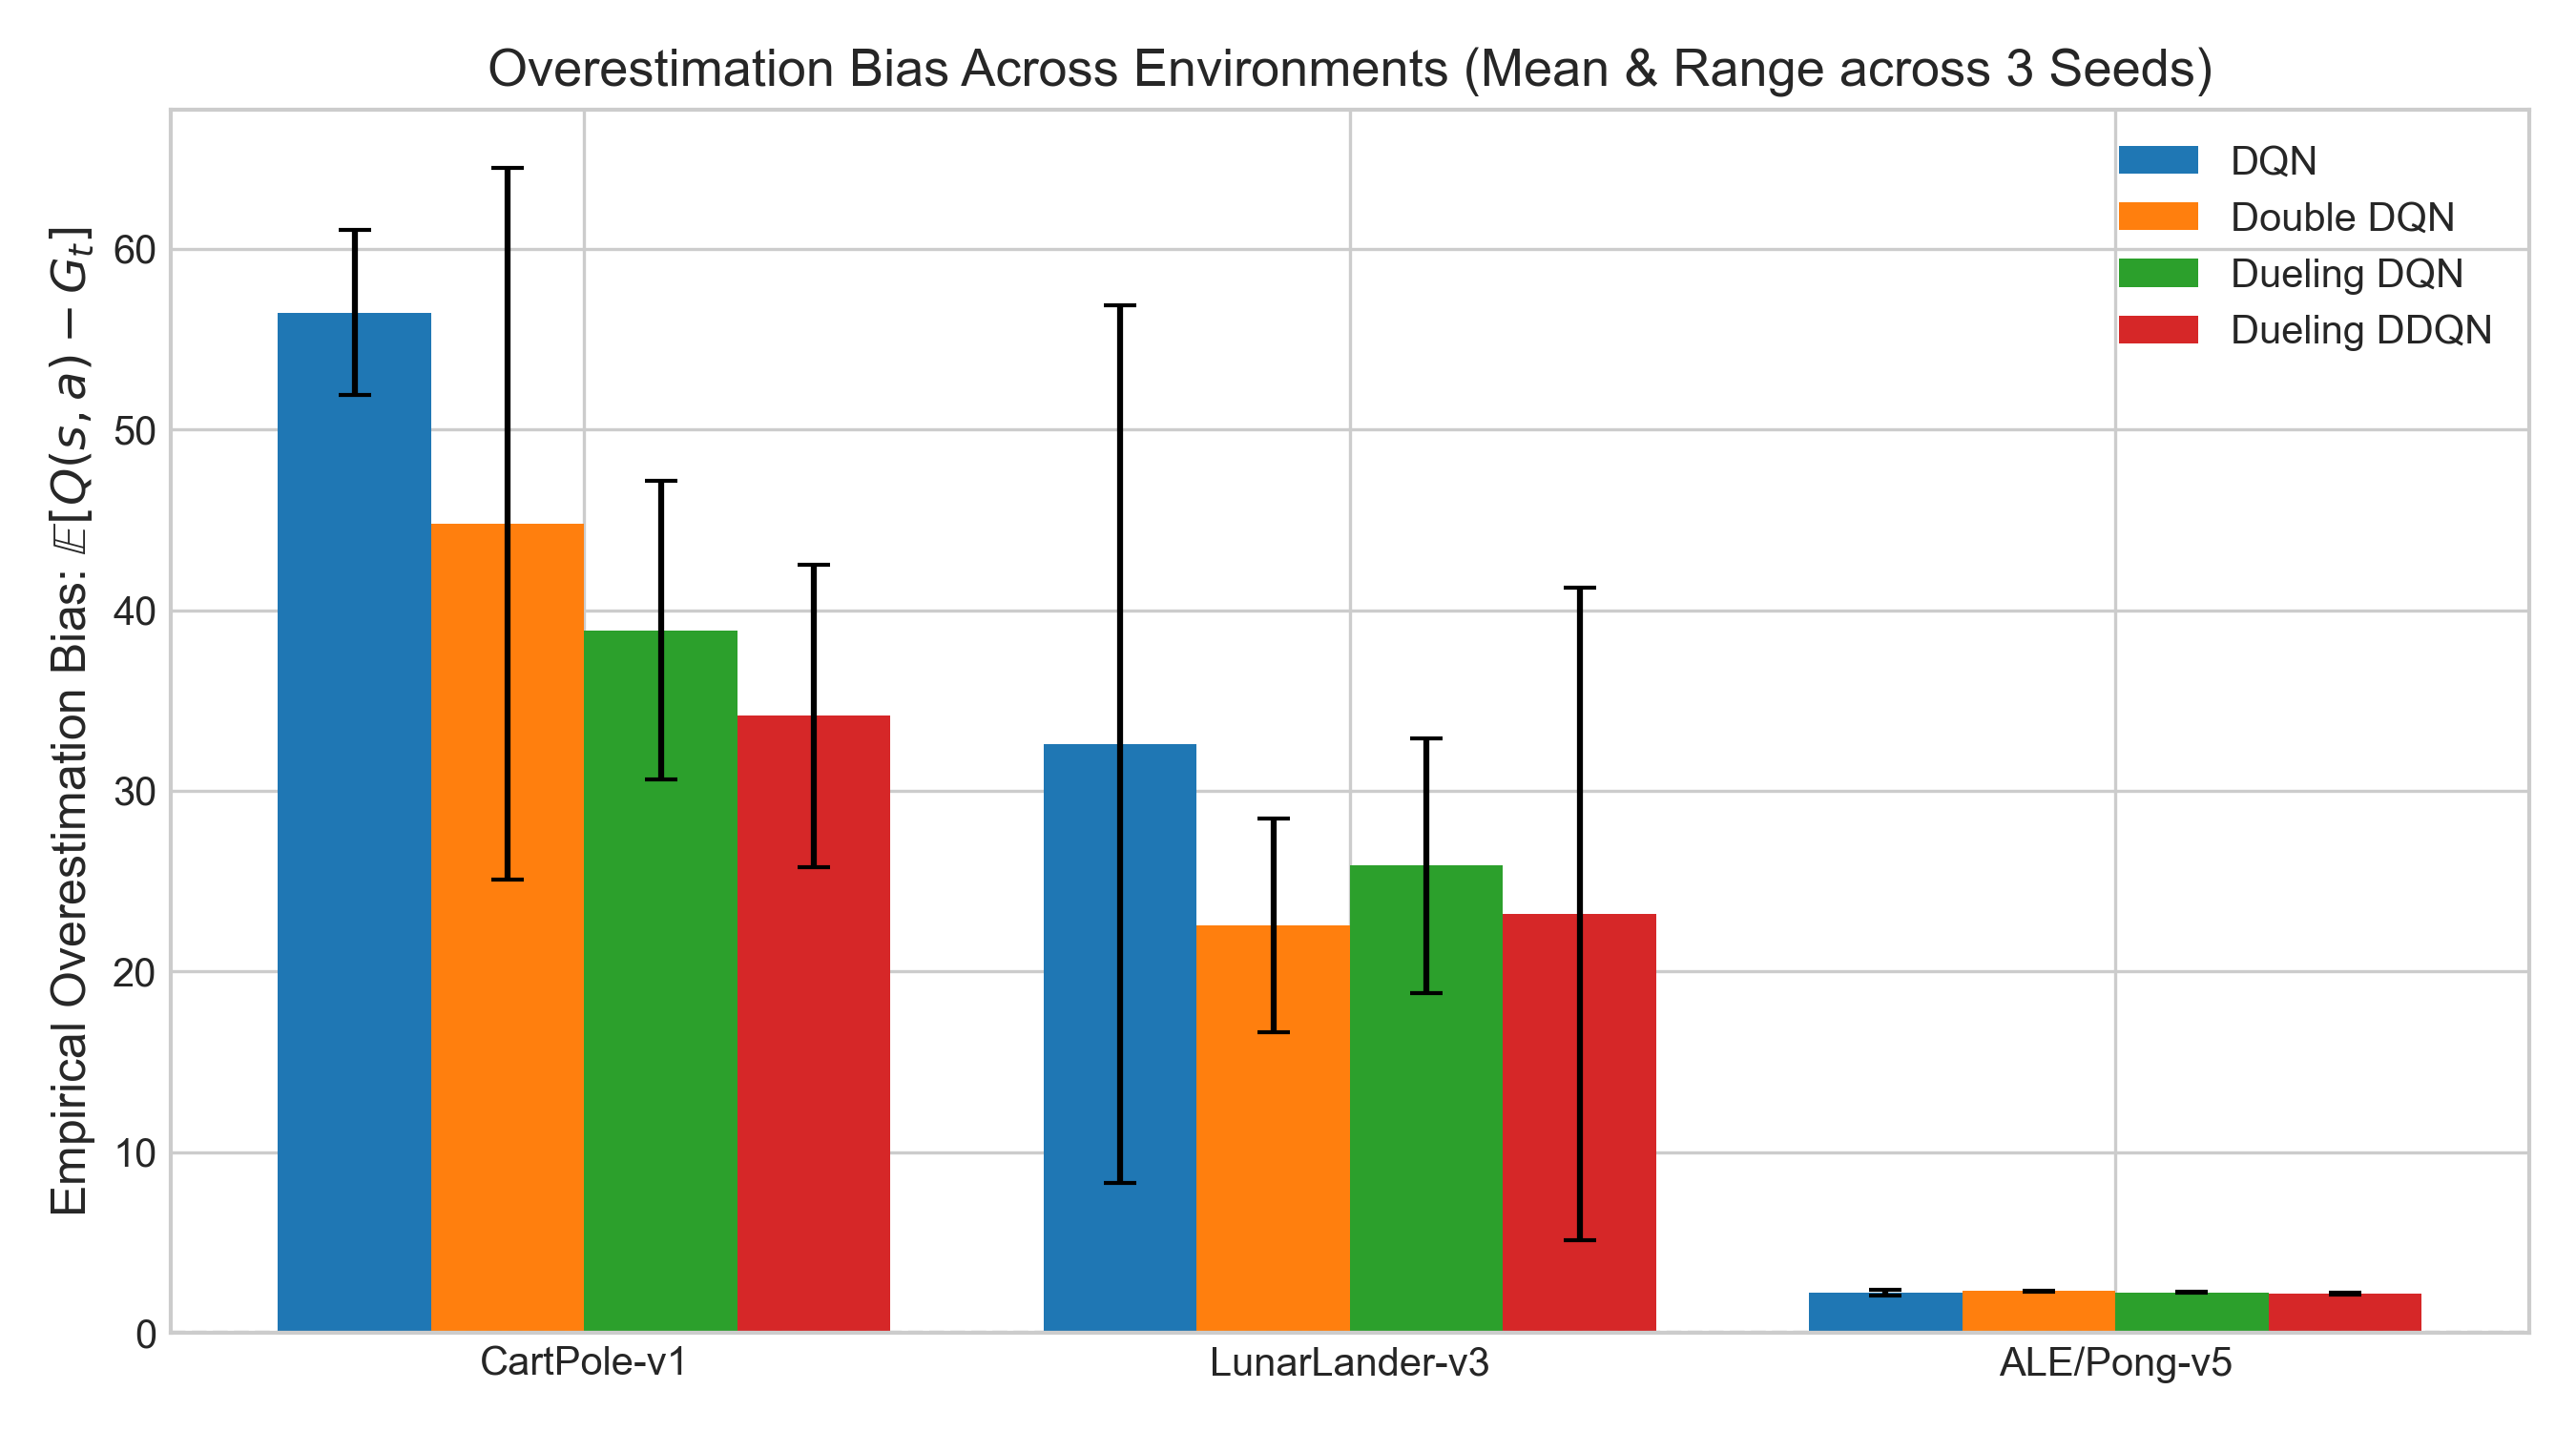

In [ ]:
# Plot Empirical Overestimation Bias Measurement E[Q(s, a) - G_t]
import os
from IPython.display import Image, display
display(Image(filename=os.path.join("figures", "ex2_overestimation_bias.png")))


### 2. Overestimation Bias & Structural Representation Analysis
1. **Maximization Bias Reduction**:
   - Baseline DQN takes the maximum over noisy estimates: $\mathbb{E}[\max_a Q(s', a')] \ge \max_a \mathbb{E}[Q(s', a')]$ (by Jensen's inequality).
   - Double DQN effectively decouples greedy action selection from its Q-value estimation, eliminating systematic overoptimism.
2. **Dueling Stream Advantage**:
   - In environments where many actions have identical consequences on survival or state transition, the agent learns the state value $V(s)$ across all actions without needing to sample every action individually.
   - Combining Dueling DQN with Double DQN provides superior sample efficiency and policy stability.
